In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Matplotlib is building the font cache; this may take a moment.


In [3]:
df = pd.read_excel("Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [14]:
print("Shape:", df.shape)

df.info()

display(df.head())

display(df.describe())

print("Columns:", df.columns.tolist())

Shape: (397884, 9)
<class 'pandas.DataFrame'>
Index: 397884 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    397884 non-null  object        
 1   StockCode    397884 non-null  object        
 2   Description  397884 non-null  object        
 3   Quantity     397884 non-null  int64         
 4   InvoiceDate  397884 non-null  datetime64[us]
 5   UnitPrice    397884 non-null  float64       
 6   CustomerID   397884 non-null  float64       
 7   Country      397884 non-null  str           
 8   TotalPrice   397884 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), object(3), str(1)
memory usage: 30.4+ MB


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


,Quantity,InvoiceDate,UnitPrice,CustomerID,TotalPrice
count,397884.000000,397884,397884.000000,397884.000000,397884.000000
mean,12.988238,2011-07-10 23:41:23.511023,3.116488,15294.423453,22.397000
min,1.000000,2010-12-01 08:26:00,0.001000,12346.000000,0.001000
25%,2.000000,2011-04-07 11:12:00,1.250000,13969.000000,4.680000
50%,6.000000,2011-07-31 14:39:00,1.950000,15159.000000,11.800000
75%,12.000000,2011-10-20 14:33:00,3.750000,16795.000000,19.800000
max,80995.000000,2011-12-09 12:50:00,8142.750000,18287.000000,168469.600000
std,179.331775,NaN,22.097877,1713.141560,309.071041


Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalPrice']


In [15]:
print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64


In [16]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 5192


In [17]:
df = df.drop_duplicates()

df = df.dropna(subset=["CustomerID"])

df = df[
    (~df["InvoiceNo"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

In [18]:

snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [19]:
X = rfm[["Recency", "Frequency", "Monetary"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

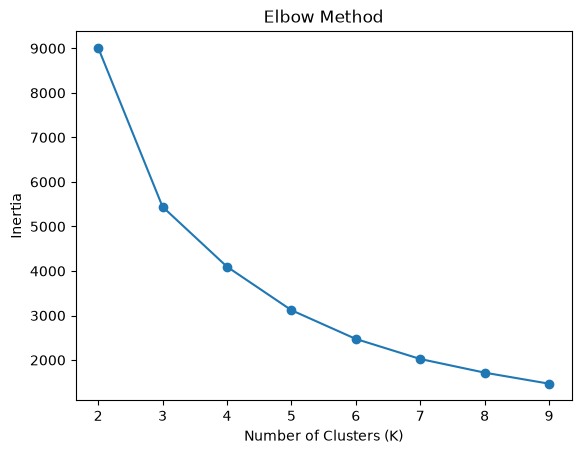

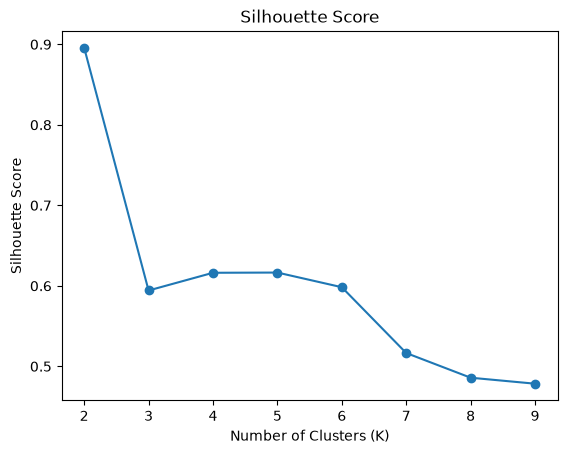

In [25]:
inertia = []
silhouette_scores = []
k_values = range(2, 10)

from sklearn.metrics import silhouette_score

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X_scaled)

    inertia.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

plt.plot(k_values, silhouette_scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score")
plt.show()

In [20]:
kmeans = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(rfm["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0    3054
1    1067
2      13
3     204
Name: count, dtype: int64


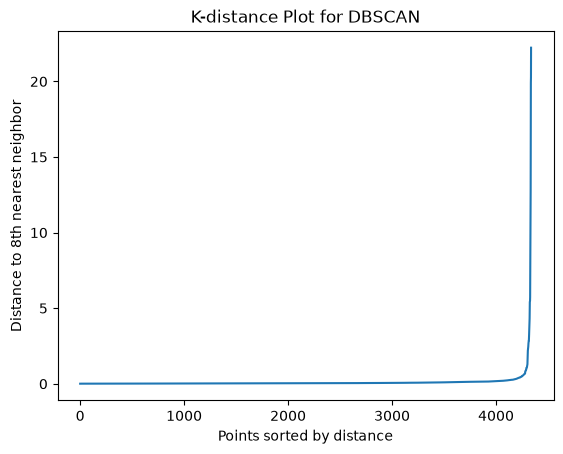

In [26]:
from sklearn.neighbors import NearestNeighbors

k = 8

nn = NearestNeighbors(n_neighbors=k)
nn.fit(X_scaled)

distances, indices = nn.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])

plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 8th nearest neighbor")
plt.title("K-distance Plot for DBSCAN")
plt.show()

In [28]:
dbscan = DBSCAN(eps=0.5, min_samples=8)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print(rfm["DBSCAN_Cluster"].value_counts().sort_index())


DBSCAN_Cluster
-1      67
 0    4271
Name: count, dtype: int64


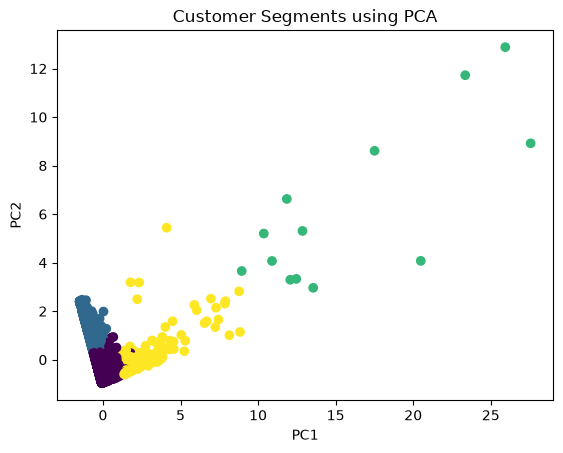

In [29]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=rfm["KMeans_Cluster"], cmap="viridis"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Customer Segments using PCA")
plt.show()

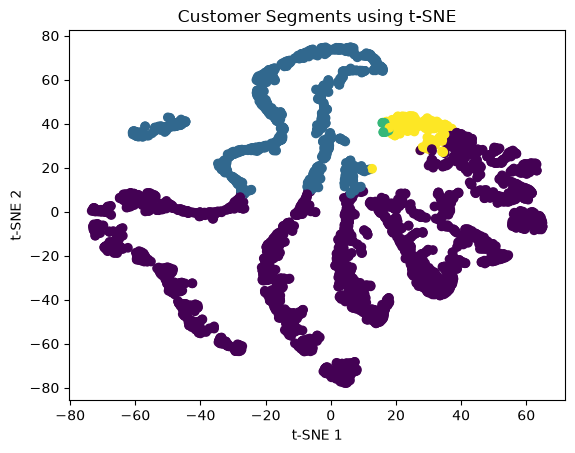

In [30]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=rfm["KMeans_Cluster"], cmap="viridis"
)

plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.title("Customer Segments using t-SNE")
plt.show()

In [31]:
profiles = rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

for cluster in profiles.index:
    r = profiles.loc[cluster, "Recency"]
    f = profiles.loc[cluster, "Frequency"]
    m = profiles.loc[cluster, "Monetary"]

    if r < profiles["Recency"].median() and f > profiles["Frequency"].median():
        persona = "Loyal Customers"
    elif r > profiles["Recency"].median():
        persona = "At-Risk Customers"
    elif m > profiles["Monetary"].median():
        persona = "High-Spending Customers"
    else:
        persona = "Regular Customers"

    profiles.loc[cluster, "Marketing_Persona"] = persona

print(profiles)

                Recency  Frequency   Monetary  Marketing_Persona
KMeans_Cluster                                                  
0                 43.70       3.68    1353.63  At-Risk Customers
1                248.08       1.55     478.85  At-Risk Customers
2                  7.38      82.54  127187.96    Loyal Customers
3                 15.50      22.33   12690.50    Loyal Customers
